In [393]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler)

from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

In [394]:
df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/breast+cancer+wisconsin+diagnostic/wdbc.data", header = None)
df

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


### Note
- Here the label contains two labels
- 'M' - malignant (means cancer)
- 'B' - benign (means Not cancer)

In [395]:
features = [
    "radius", "texture", "perimeter", "area",
    "smoothness", "compactness", "concavity",
    "concave_points", "symmetry", "fractal_dimension"
]

columns = ["id", "diagnosis"]

for suffix in ["mean", "se", "worst"]:
    for feature in features:
        columns.append(f"{feature}_{suffix}")

df.columns = columns

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [396]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [397]:
x = df.drop(columns=["diagnosis","id"])
y = df["diagnosis"]

In [398]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

## Scaling

In [399]:
numerical_columns = x.select_dtypes(include = 'number')        # include = ('int','float')
numerical_columns

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


### Analysing the outliers in each of the columns using boxplot

In [400]:
for i in numerical_columns.columns:
    print(f'plt.boxplot(df["{i}"])')


plt.boxplot(df["radius_mean"])
plt.boxplot(df["texture_mean"])
plt.boxplot(df["perimeter_mean"])
plt.boxplot(df["area_mean"])
plt.boxplot(df["smoothness_mean"])
plt.boxplot(df["compactness_mean"])
plt.boxplot(df["concavity_mean"])
plt.boxplot(df["concave_points_mean"])
plt.boxplot(df["symmetry_mean"])
plt.boxplot(df["fractal_dimension_mean"])
plt.boxplot(df["radius_se"])
plt.boxplot(df["texture_se"])
plt.boxplot(df["perimeter_se"])
plt.boxplot(df["area_se"])
plt.boxplot(df["smoothness_se"])
plt.boxplot(df["compactness_se"])
plt.boxplot(df["concavity_se"])
plt.boxplot(df["concave_points_se"])
plt.boxplot(df["symmetry_se"])
plt.boxplot(df["fractal_dimension_se"])
plt.boxplot(df["radius_worst"])
plt.boxplot(df["texture_worst"])
plt.boxplot(df["perimeter_worst"])
plt.boxplot(df["area_worst"])
plt.boxplot(df["smoothness_worst"])
plt.boxplot(df["compactness_worst"])
plt.boxplot(df["concavity_worst"])
plt.boxplot(df["concave_points_worst"])
plt.boxplot(df["symmetry_worst"])
plt.boxplot(df["fr

{'whiskers': [<matplotlib.lines.Line2D at 0x73240ed3de20>,
 'caps': [<matplotlib.lines.Line2D at 0x73240ed3cb60>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ee8d970>],
 'medians': [<matplotlib.lines.Line2D at 0x73240ed3cfe0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240ed3cd40>],
 'means': []}

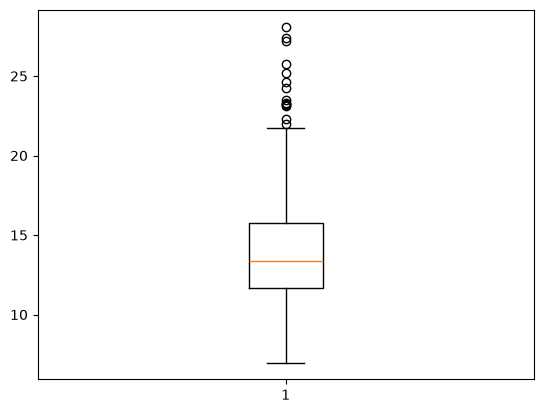

In [401]:
plt.boxplot(df["radius_mean"])

{'whiskers': [<matplotlib.lines.Line2D at 0x73240edee180>,
 'caps': [<matplotlib.lines.Line2D at 0x73240edee6c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240eded790>],
 'medians': [<matplotlib.lines.Line2D at 0x73240edeec00>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240edeeea0>],
 'means': []}

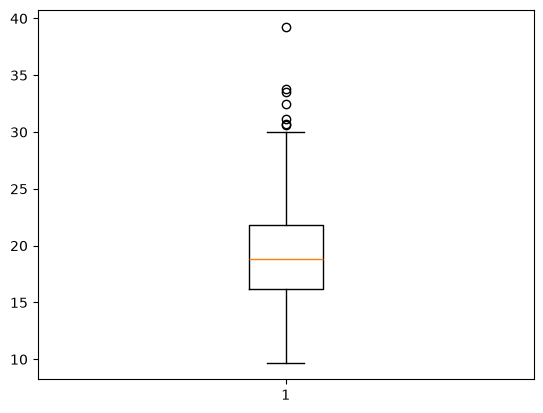

In [402]:
plt.boxplot(df["texture_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240ec41580>,
 'caps': [<matplotlib.lines.Line2D at 0x73240ec41ac0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ec09dc0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240ec42000>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240ec422a0>],
 'means': []}

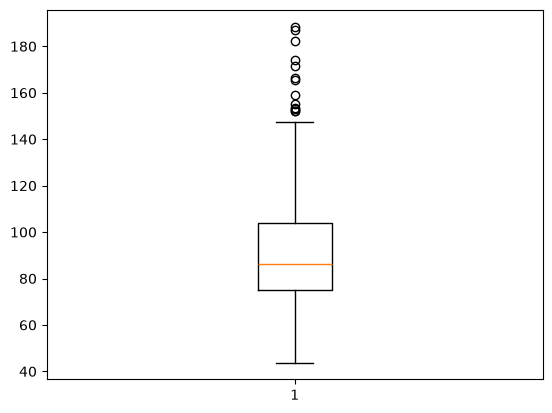

In [403]:
plt.boxplot(df["perimeter_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240ec9cd70>,
 'caps': [<matplotlib.lines.Line2D at 0x73240ec9d280>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ec9cad0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240ec9d7c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240ec9da30>],
 'means': []}

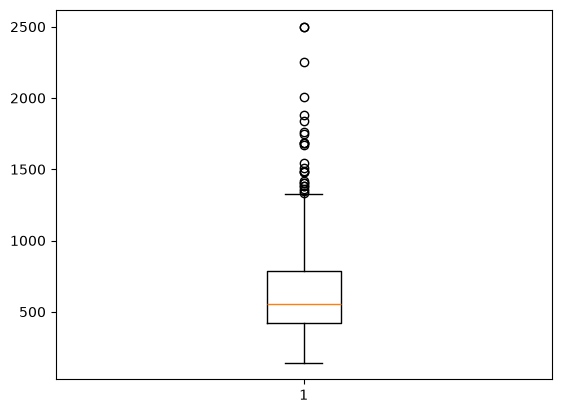

In [404]:
plt.boxplot(df["area_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240ece2720>,
 'caps': [<matplotlib.lines.Line2D at 0x73240ece2c60>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ecc9c40>],
 'medians': [<matplotlib.lines.Line2D at 0x73240ece3140>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240ece3350>],
 'means': []}

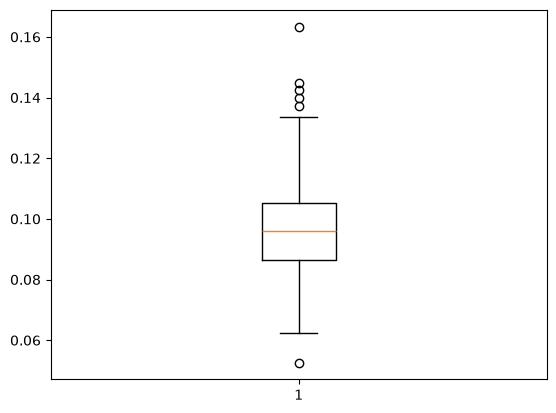

In [405]:
plt.boxplot(df["smoothness_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240eb50350>,
 'caps': [<matplotlib.lines.Line2D at 0x73240eb50770>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240eb500b0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240eb50c80>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240eb50f20>],
 'means': []}

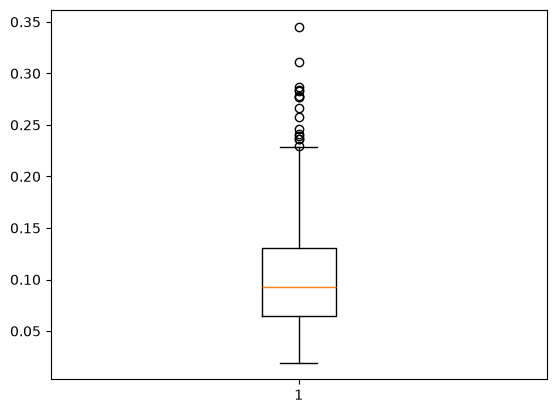

In [406]:
plt.boxplot(df["compactness_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240eb86d80>,
 'caps': [<matplotlib.lines.Line2D at 0x73240eb872c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240eb86ae0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240eb87800>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240eb87aa0>],
 'means': []}

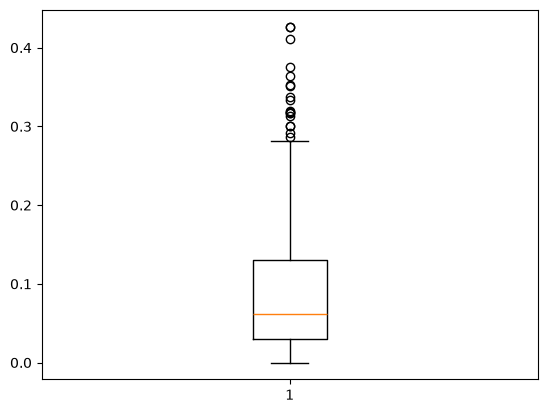

In [407]:
plt.boxplot(df["concavity_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240ebec680>,
 'caps': [<matplotlib.lines.Line2D at 0x73240ebecbc0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ebec440>],
 'medians': [<matplotlib.lines.Line2D at 0x73240ebed100>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240ebcb230>],
 'means': []}

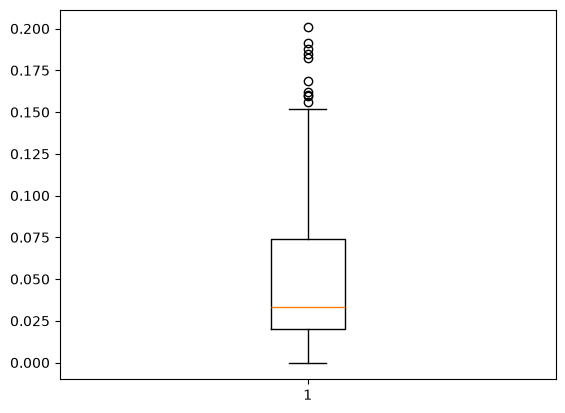

In [408]:
plt.boxplot(df["concave_points_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240ea54440>,
 'caps': [<matplotlib.lines.Line2D at 0x73240ea54980>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ea541a0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240ea54e90>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240ea55130>],
 'means': []}

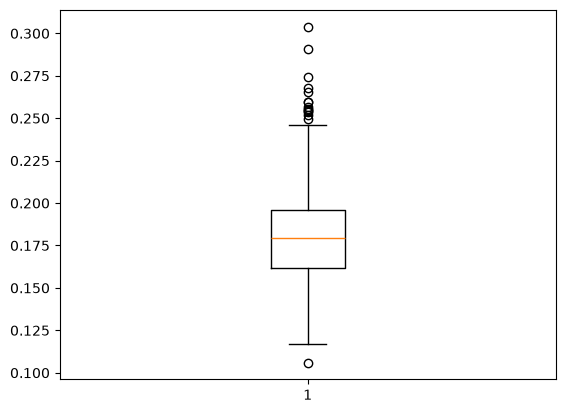

In [409]:
plt.boxplot(df["symmetry_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240ea7fe60>,
 'caps': [<matplotlib.lines.Line2D at 0x73240eab43e0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240ea7cec0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240eab48f0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240eab4b60>],
 'means': []}

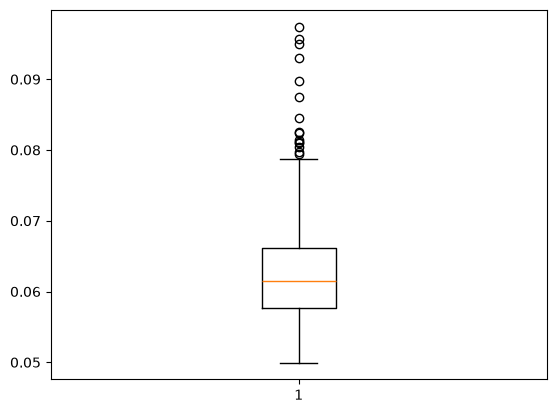

In [410]:
plt.boxplot(df["fractal_dimension_mean"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240eaf4e30>,
 'caps': [<matplotlib.lines.Line2D at 0x73240eaf5370>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240eaf4b60>],
 'medians': [<matplotlib.lines.Line2D at 0x73240eaf58b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240eaf5b50>],
 'means': []}

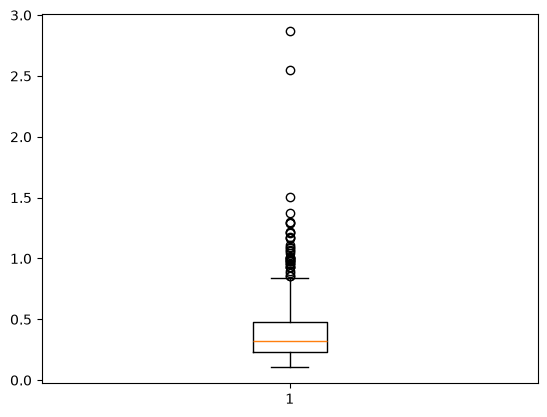

In [411]:
plt.boxplot(df["radius_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e936f00>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e937440>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e91f050>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e937980>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e937c20>],
 'means': []}

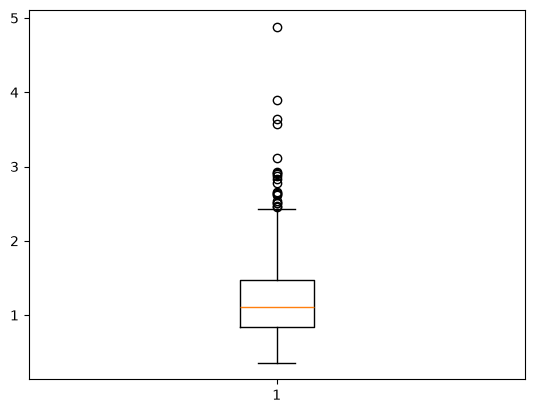

In [412]:
plt.boxplot(df["texture_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e983a70>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e983fb0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e983800>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e9a8530>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e9a87d0>],
 'means': []}

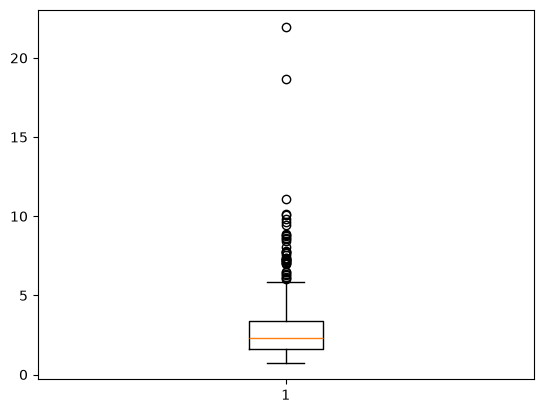

In [413]:
plt.boxplot(df["perimeter_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e9f4dd0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e9f5310>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e9a9dc0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e9f5850>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e9cafc0>],
 'means': []}

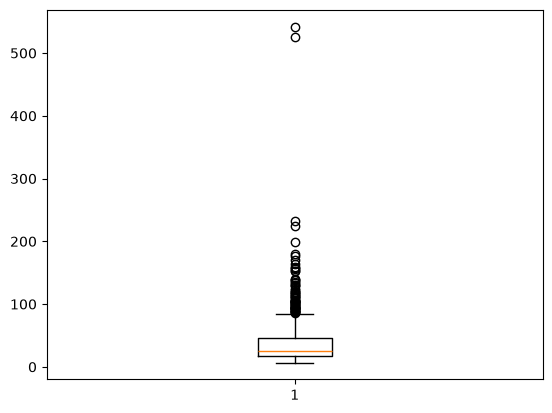

In [414]:
plt.boxplot(df["area_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e82b0e0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e82b4d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e82ae70>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e82b9e0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e82bc80>],
 'means': []}

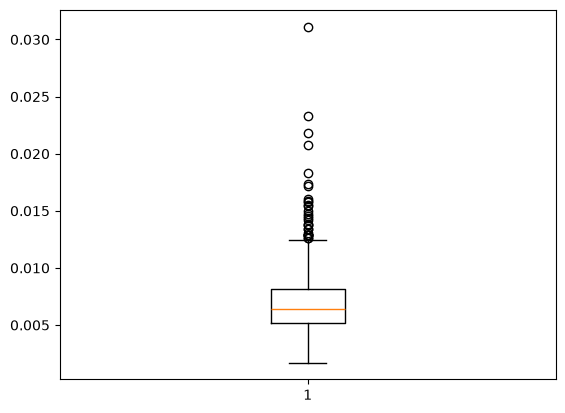

In [415]:
plt.boxplot(df["smoothness_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e891550>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e891a90>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e8912b0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e891fd0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e892240>],
 'means': []}

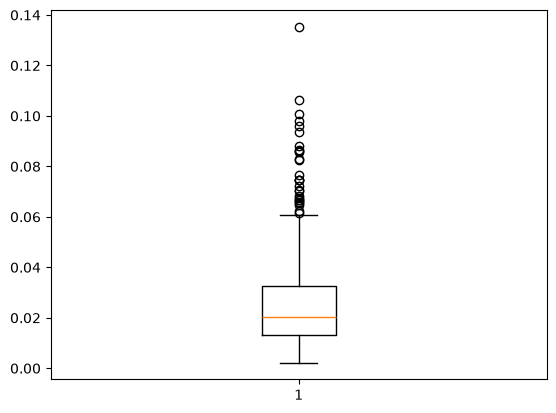

In [416]:
plt.boxplot(df["compactness_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x732411bae450>,
 'caps': [<matplotlib.lines.Line2D at 0x732411baec90>,
 'boxes': [<matplotlib.lines.Line2D at 0x732411bad640>],
 'medians': [<matplotlib.lines.Line2D at 0x732411b4a060>],
 'fliers': [<matplotlib.lines.Line2D at 0x732411b49340>],
 'means': []}

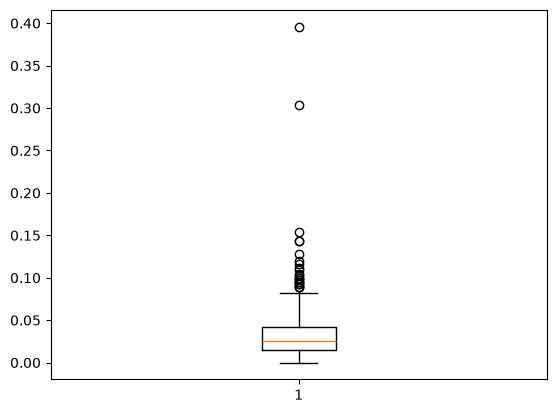

In [417]:
plt.boxplot(df["concavity_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x732411a07bf0>,
 'caps': [<matplotlib.lines.Line2D at 0x732411e42030>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e8924b0>],
 'medians': [<matplotlib.lines.Line2D at 0x732411e433b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e874770>],
 'means': []}

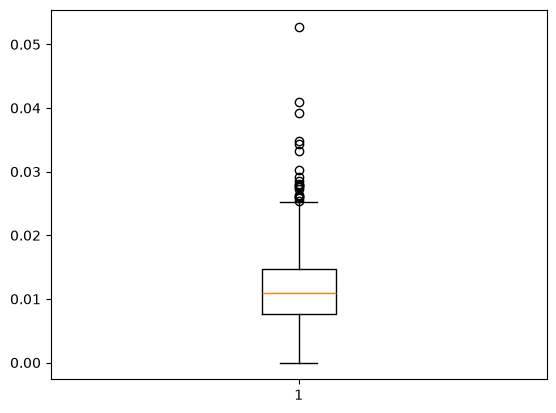

In [418]:
plt.boxplot(df["concave_points_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e770770>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e770c80>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e7705f0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e7711c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e771430>],
 'means': []}

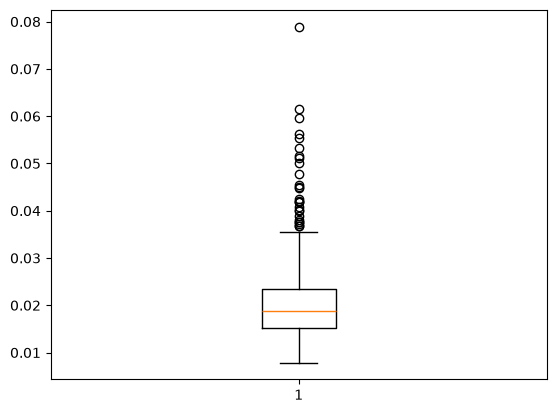

In [419]:
plt.boxplot(df["symmetry_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e7bd460>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e7bd9a0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e7bd190>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e7bde20>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e7be0c0>],
 'means': []}

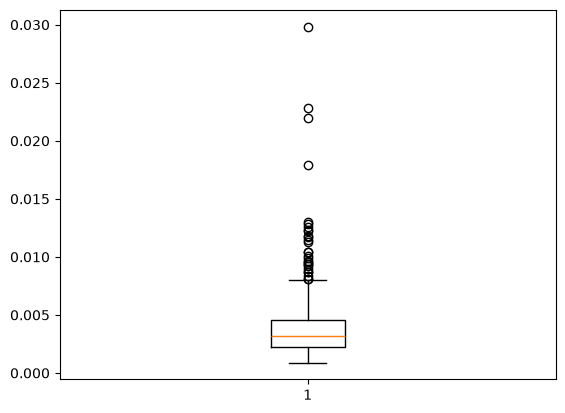

In [420]:
plt.boxplot(df["fractal_dimension_se"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e618c50>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e619190>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e7f1dc0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e6196d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e619970>],
 'means': []}

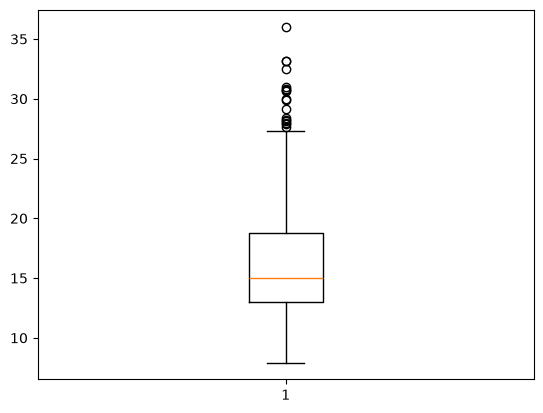

In [421]:
plt.boxplot(df["radius_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e653a70>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e653fb0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e6538f0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e67c500>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e67c7a0>],
 'means': []}

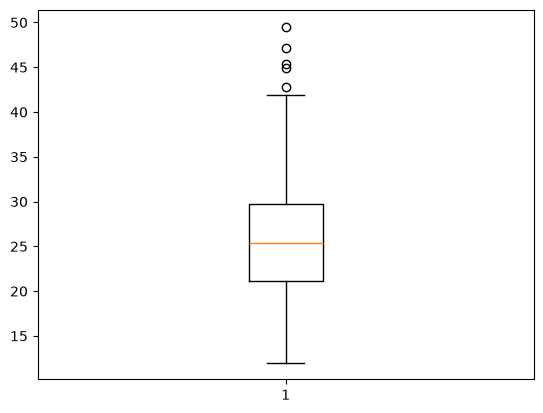

In [422]:
plt.boxplot(df["texture_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e6afce0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e653620>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e6afad0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e6d06b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e6d0950>],
 'means': []}

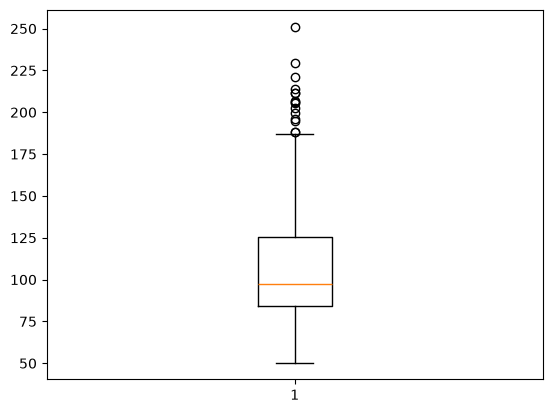

In [423]:
plt.boxplot(df["perimeter_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e520da0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e5212b0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e501dc0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e5216a0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e521940>],
 'means': []}

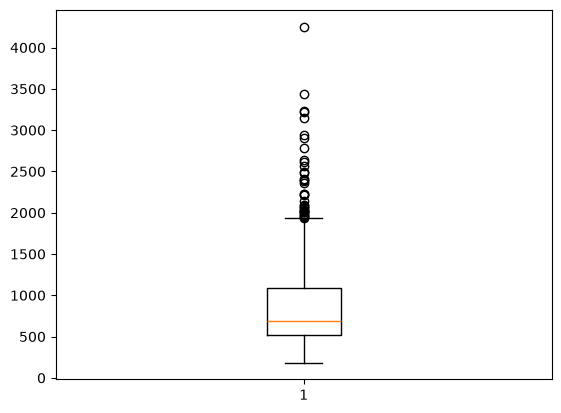

In [424]:
plt.boxplot(df["area_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e56ab40>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e56b050>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e56a8d0>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e56b590>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e56b830>],
 'means': []}

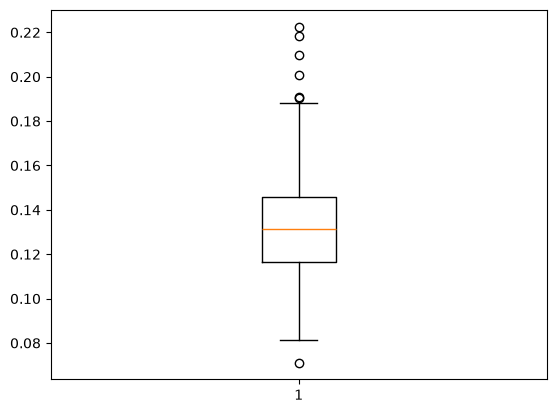

In [425]:
plt.boxplot(df["smoothness_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e5bf230>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e5bf740>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e5bef60>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e5bfc50>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e5bfef0>],
 'means': []}

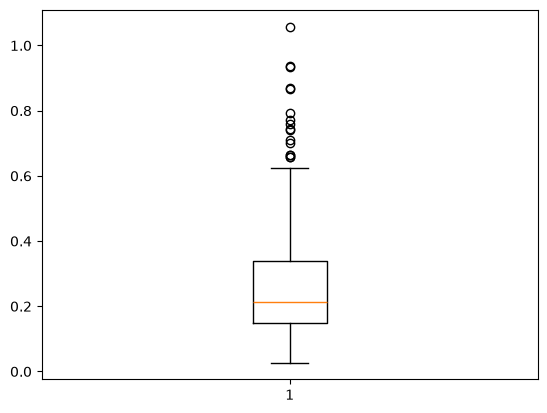

In [426]:
plt.boxplot(df["compactness_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e4297f0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e429d30>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e429550>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e42a270>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e42a510>],
 'means': []}

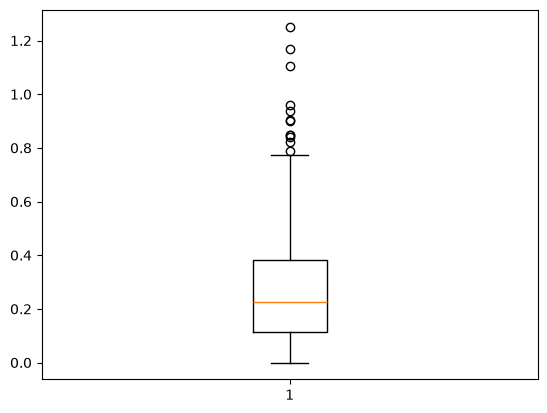

In [427]:
plt.boxplot(df["concavity_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e488a40>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e488f80>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e488260>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e4894c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e489760>],
 'means': []}

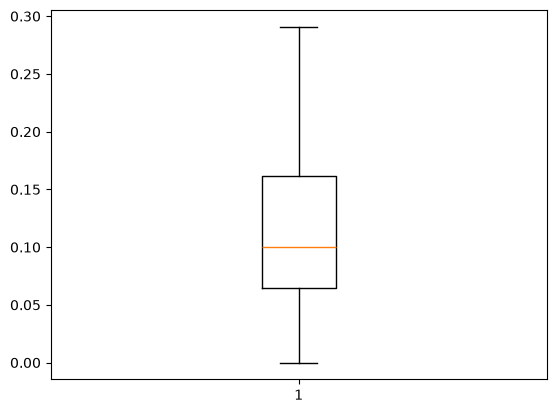

In [428]:
plt.boxplot(df["concave_points_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e4e4aa0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e4e4fb0>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e4e4830>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e4e5460>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e4e5700>],
 'means': []}

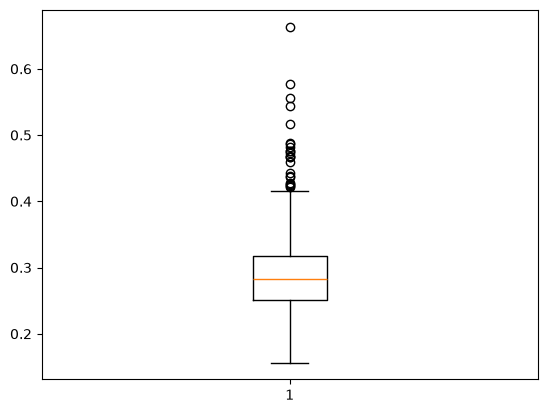

In [429]:
plt.boxplot(df["symmetry_worst"])


{'whiskers': [<matplotlib.lines.Line2D at 0x73240e32b2f0>,
 'caps': [<matplotlib.lines.Line2D at 0x73240e32b710>,
 'boxes': [<matplotlib.lines.Line2D at 0x73240e32b050>],
 'medians': [<matplotlib.lines.Line2D at 0x73240e32bbf0>],
 'fliers': [<matplotlib.lines.Line2D at 0x73240e32be60>],
 'means': []}

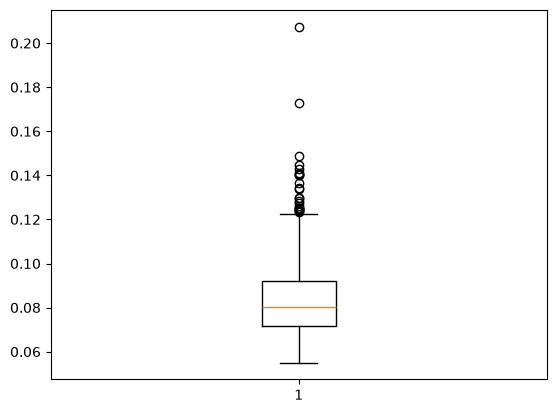

In [430]:
plt.boxplot(df["fractal_dimension_worst"])

### Based on this , deciding which columns needs which scaling techniques.

In [431]:
# columns_for_standard_scaler = []
# columns_for_standard_scaler.append(numerical_columns.columns[0:10])
# columns_for_standard_scaler.append(numerical_columns.columns[[11,21,22,24,25,26]])

# columns_for_standard_scaler

In [432]:
columns_for_standard_scaler = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
        'smoothness_mean', 'compactness_mean', 'concavity_mean',
        'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean','texture_se', 'texture_worst', 'perimeter_worst', 'smoothness_worst',
        'compactness_worst', 'concavity_worst']

In [433]:
# columns_for_robust_scaler = []
# columns_for_robust_scaler.append(numerical_columns.columns[[10]])
# columns_for_robust_scaler.append(numerical_columns.columns[12:21])
# columns_for_robust_scaler.append(numerical_columns.columns[[23,28,29]])

# columns_for_robust_scaler


In [434]:
columns_for_robust_scaler = ['radius_se','perimeter_se', 'area_se', 'smoothness_se', 'compactness_se',
        'concavity_se', 'concave_points_se', 'symmetry_se',
        'fractal_dimension_se', 'radius_worst','area_worst', 'symmetry_worst', 'fractal_dimension_worst']

In [435]:
column_for_min_max_scaler = ['concave_points_worst']

In [436]:
standard_scalar = StandardScaler()
robust_scalar = RobustScaler()
min_max_scaler = MinMaxScaler()

In [437]:
x_train[columns_for_standard_scaler] = standard_scalar.fit_transform(x_train[columns_for_standard_scaler])
x_train[columns_for_robust_scaler] = robust_scalar.fit_transform(x_train[columns_for_robust_scaler])
x_train[column_for_min_max_scaler] = min_max_scaler.fit_transform(x_train[column_for_min_max_scaler])
x_train.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
68,-1.440753,-0.435319,-1.362085,-1.139118,0.780573,0.718921,2.823135,-0.119150,1.092662,2.458173,...,-0.870215,-0.476309,-1.247920,-0.702650,0.722894,1.186732,4.672828,0.601375,2.052747,1.781161
181,1.974096,1.733026,2.091672,1.851973,1.319843,3.426275,2.013112,2.665032,2.127004,1.558396,...,2.186741,1.311279,2.081617,2.722842,0.761928,3.265601,1.928621,0.997595,1.862271,2.299715
63,-1.399982,-1.249622,-1.345209,-1.109785,-1.332645,-0.307355,-0.365558,-0.696502,1.930333,0.954379,...,-0.926237,-1.040811,-1.245220,-0.730997,-1.438693,-0.548564,-0.644911,0.174811,0.666667,0.230257
248,-0.981797,1.416222,-0.982587,-0.866944,0.059390,-0.596788,-0.820203,-0.845115,0.313264,0.074041,...,-0.507937,1.593530,-0.873572,-0.448306,0.796624,-0.729392,-0.774950,0.210859,0.852747,0.067079
60,-1.117700,-1.010259,-1.125002,-0.965942,1.269511,-0.439002,-0.983341,-0.930600,3.394436,0.950213,...,-0.737628,-1.334616,-1.117138,-0.617416,-0.174876,-0.995079,-1.209146,0.088625,1.069597,0.006660


In [438]:
x_test[columns_for_standard_scaler] = standard_scalar.transform(x_test[columns_for_standard_scaler])
x_test[columns_for_robust_scaler] = robust_scalar.transform(x_test[columns_for_robust_scaler])
x_test[column_for_min_max_scaler] = min_max_scaler.transform(x_test[column_for_min_max_scaler])
x_test.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
204,-0.466497,-0.137289,-0.444211,-0.486465,0.280850,0.041606,-0.111465,-0.264869,0.415241,0.135137,...,0.000000,-0.147842,-0.331548,-0.016892,0.480019,-0.096496,-0.035830,0.348797,0.273993,0.353949
70,1.365363,0.498665,1.305511,1.341471,-0.406539,-0.013724,0.240637,0.821449,-0.833981,-1.131215,...,1.846872,0.172372,1.763661,2.289875,-0.530514,-0.123620,-0.028181,0.614777,-0.404396,-0.674120
131,0.380066,0.069220,0.404101,0.266596,0.967520,0.356414,0.726902,0.857221,0.437094,-0.666053,...,0.801120,0.076638,0.533832,0.911368,1.000466,-0.086163,0.499625,0.520275,0.014652,0.006185
431,-0.486317,-0.353185,-0.428570,-0.526233,0.694290,0.533852,-0.144722,-0.533686,0.000048,1.147386,...,-0.390289,-0.433394,-0.524721,-0.331618,0.584109,0.065603,-0.163957,0.253265,-0.397070,0.643673
540,-0.729810,-1.113514,-0.709283,-0.709281,0.294512,0.159898,-0.271202,-0.587608,0.025542,0.703052,...,-0.506069,-0.966535,-0.849575,-0.444229,0.128718,-0.264407,-0.453677,0.237732,-0.729670,0.060894


## Encoding

Observational Note:
- Here the only string based categorical column is the target column 'diagnosis'
- so we are using label_encoder for encoding this column

In [439]:
# Creating object of the LabelEncoder

label_encoder = LabelEncoder()

In [440]:
y_train

68     B
181    M
63     B
248    B
60     B
      ..
71     B
106    B
270    B
435    M
102    B
Name: diagnosis, Length: 455, dtype: str

In [441]:
y_train = label_encoder.fit_transform(y_train)

y_test = label_encoder.transform(y_test)

In [442]:
y_train

array([0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,

In [443]:
y_test

array([0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 1])

### Modeling

In [444]:
model = LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [445]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

### Model Performance evaluation by the classification metrics

In [446]:
y.value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [447]:
print(f'percentage of B samples {(357/(357+212))*100}\npercentage of M samples {(212/(357+212))*100}')

percentage of B samples 62.741652021089635
percentage of M samples 37.258347978910365


Conclusion:
- Dataset is imbalenced
- usage of accuracy metric can give misleading information

In [448]:
# 1. confusion matrix:
# on train data

cf_train = confusion_matrix(y_train,y_train_pred)

cf_train

array([[284,   2],
       [  4, 165]])

Note:
- here first row (and column) represents the 0 ('B'-not cancer)
- here second row (and column) represents the 1 ('M'-Cancer)

In [449]:
# 2. recall score (i.e row-wise)

# for label =0 i.e 'not cancer'


recall_score_for_B = cf_train[0,0] / (cf_train[0,0] + cf_train[0,1])

recall_score_for_B

np.float64(0.993006993006993)

conclusion:
- out of 286 'B'-not cancer samples, 
- 99.3% samples are correctly predicted as not cancer,
- and remaining 0.7% samples are wrongly predicted as 'cancer' i.e 'M' (malignant)

In [450]:
# recall score for label =1 i.e 'malignant'/'cancer'
# i.e row-wise

recall_score_for_M = cf_train[1,1] / (cf_train[1,1] + cf_train[1,0])

recall_score_for_M

np.float64(0.9763313609467456)

conclusion:
- out of 169 'M'-cancer samples, 
- 97.6% samples are correctly predicted as cancer,
- and remaining 2.4% samples are wrongly predicted as 'not cancer' i.e 'B' (benign)

In [451]:
# 3. precision score (i.e column-wise)

# for label =0 i.e 'not cancer'


precision_score_for_B = cf_train[0,0] / (cf_train[0,0] + cf_train[1,0])

precision_score_for_B

np.float64(0.9861111111111112)

conclusion:
- out of 288 samples predicted as 'B'-not cancer, 
- 98.6% samples are actually 'B'-not cancer samples
- and remaining 1.4% samples are wrongly predicted as 'B'-not cancer

In [452]:
# precision score for label =1 i.e 'malignant'/'cancer'
# i.e column-wise

precision_score_for_M = cf_train[1,1] / (cf_train[1,1] + cf_train[0,1])

precision_score_for_M

np.float64(0.9880239520958084)

conclusion:
- out of 167 samples predicted as 'M'-cancer, 
- 98.8% samples are actually 'M'-cancer samples
- and remaining 1.2% samples are wrongly predicted as 'M'-cancer

In [453]:
cf_test = confusion_matrix(y_test,y_test_pred)

cf_test

array([[70,  1],
       [ 1, 42]])

### Directly calling recall and precision values 

In [454]:
print(f'Recall score for B (no cancer) : {recall_score(y_train,y_train_pred,pos_label = 0)}')
print(f'Recall score for M (cancer): {recall_score(y_train,y_train_pred,pos_label = 1)}')

Recall score for B (no cancer) : 0.993006993006993
Recall score for M (cancer): 0.9763313609467456


In [455]:
print(f'Precision score for B (no cancer): {precision_score(y_train,y_train_pred,pos_label = 0)}')
print(f'Precision score for M (cancer): {precision_score(y_train,y_train_pred,pos_label = 1)}')


Precision score for B (no cancer): 0.9861111111111112
Precision score for M (cancer): 0.9880239520958084
